# 1. 이미지 데이터

## 1-1. 이미지 파일과 레이블 CSV 생성

- 먼저 원, 사각형, 삼각형 이미지를 각각 10장씩 생성
- 별도로 이미지를 준비하지 않아도 실습할 수 있도록 Python으로 간단한 도형 이미지를 만듦

In [17]:
from pathlib import Path

import pandas as pd
from PIL import Image, ImageDraw


# 1. 데이터 저장 경로
root = Path("image_loader_practice")
image_dir = root / "images"

image_dir.mkdir(
    parents=True,
    exist_ok=True
)


# 2. 클래스별 레이블 정의
class_names = {
    0: "circle",
    1: "square",
    2: "triangle"
}

records = []


# 3. 클래스마다 이미지 10장 생성
for label, name in class_names.items():

    for i in range(10):

        image = Image.new(
            "RGB",
            (96, 96),
            "white"
        )

        draw = ImageDraw.Draw(image)

        # 이미지 위치를 조금씩 변경
        offset = (i % 5 - 2) * 3

        if label == 0:
            draw.ellipse(
                (20 + offset, 20, 76 + offset, 76),
                fill="tomato"
            )

        elif label == 1:
            draw.rectangle(
                (20 + offset, 20, 76 + offset, 76),
                fill="royalblue"
            )

        else:
            draw.polygon(
                [
                    (48 + offset, 15),
                    (18 + offset, 78),
                    (78 + offset, 78)
                ],
                fill="seagreen"
            )

        # 이미지 파일 저장
        filename = f"{name}_{i:02d}.png"

        image.save(image_dir / filename)

        # 이미지 파일명과 레이블 연결
        records.append({
            "filename": filename,
            "label": label
        })


# 4. 레이블 CSV 저장
labels_df = pd.DataFrame(records)

csv_path = root / "labels.csv"

labels_df.to_csv(
    csv_path,
    index=False
)


# 5. 결과 확인
print("전체 이미지 수:", len(labels_df))
print(labels_df.head())

print("\n클래스별 이미지 수:")
print(labels_df["label"].value_counts().sort_index())

전체 이미지 수: 30
        filename  label
0  circle_00.png      0
1  circle_01.png      0
2  circle_02.png      0
3  circle_03.png      0
4  circle_04.png      0

클래스별 이미지 수:
label
0    10
1    10
2    10
Name: count, dtype: int64


## 1-2. Dataset 클래스 만들기

- 이번 코드에서 생성한 이미지 파일과 레이블 CSV를 읽어오는 Dataset을 만듦

In [18]:
import pandas as pd

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset


class ImageCSVDataset(Dataset):

    def __init__(
        self,
        csv_path,
        image_dir,
        transform=None
    ):
        # 레이블 CSV 읽기
        self.data = pd.read_csv(csv_path)

        # 이미지가 저장된 경로
        self.image_dir = Path(image_dir)

        # 이미지 전처리
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        # 1. CSV에서 해당 행 가져오기
        row = self.data.iloc[index]

        # 2. 이미지 파일 경로 생성
        image_path = (
            self.image_dir / row["filename"]
        )

        # 3. 이미지 파일 읽기
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # 4. 이미지 전처리
        if self.transform is not None:
            image = self.transform(image)

        # 5. 정답 레이블 가져오기
        label = int(row["label"])

        return image, label

## 1-3. Dataset 생성 및 데이터 분할

- 앞에서 정의한 Dataset 클래스를 이용하여 실제 Dataset 객체를 생성

- 이 코드는 이전에 생성한 `image_loader_practice/images` 폴더와 `labels.csv` 파일을 사용합니다. 따라서 먼저 `1. 이미지 파일과 레이블 CSV 생성` 코드를 실행해야 함

- Dataset 클래스는 이 코드에서도 다시 정의하므로, 앞선 클래스 정의 코드를 별도로 실행할 필요는 없음

In [19]:
import torch
import pandas as pd

from torchvision import transforms
from torch.utils.data import random_split
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset


# 0. ImageCSV Dataset 정의
class ImageCSVDataset(Dataset):
    def __init__(
        self,
        csv_path,
        image_dir,
        transform=None
    ):
        # 레이블 CSV 읽기
        self.data = pd.read_csv(csv_path)

        # 이미지가 저장된 경로
        self.image_dir = Path(image_dir)

        # 이미지 전처리
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        # 1. CSV에서 해당 행 가져오기
        row = self.data.iloc[index]

        # 2. 이미지 파일 경로 생성
        image_path = (
            self.image_dir / row["filename"]
        )

        # 3. 이미지 파일 읽기
        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # 4. 이미지 전처리
        if self.transform is not None:
            image = self.transform(image)

        # 5. 정답 레이블 가져오기
        label = int(row["label"])

        return image, label
    

# 1. 이미지 전처리
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])


# 2. Dataset 생성
dataset = ImageCSVDataset(
    csv_path="image_loader_practice/labels.csv",
    image_dir="image_loader_practice/images",
    transform=transform
)


# 3. Dataset 확인
print("전체 데이터 수:", len(dataset))

image, label = dataset[0]

print("첫 번째 이미지 형태:", image.shape)
print("첫 번째 이미지 레이블:", label)


# 4. 학습/검증 데이터 분할
train_size = int(len(dataset) * 0.8)
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("학습 데이터:", len(train_dataset))
print("검증 데이터:", len(val_dataset))

전체 데이터 수: 30
첫 번째 이미지 형태: torch.Size([3, 64, 64])
첫 번째 이미지 레이블: 0
학습 데이터: 24
검증 데이터: 6


## 1-4. DataLoader 생성

- 이 코드에서는 학습 데이터와 검증 데이터를 배치 단위로 가져오도록 DataLoader를 생성함

In [20]:
from torch.utils.data import DataLoader


# 1. 학습용 DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)


# 2. 검증용 DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)


# 3. 배치 하나 가져오기
images, labels = next(iter(train_loader))


# 4. 배치 형태 확인
print("이미지 배치:", images.shape)
print("레이블 배치:", labels.shape)
print("레이블:", labels.tolist())

이미지 배치: torch.Size([4, 3, 64, 64])
레이블 배치: torch.Size([4])
레이블: [1, 0, 1, 0]


## 1-5. 배치 이미지 시각화

- 배치에 포함된 이미지와 레이블을 직접 확인해보는 코드

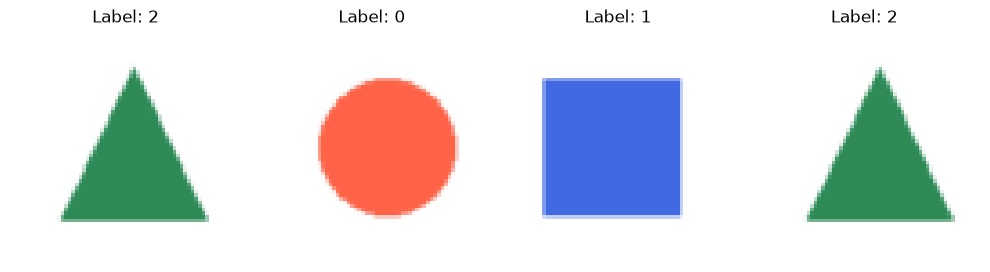

In [21]:
import matplotlib.pyplot as plt


# 배치 하나 가져오기
images, labels = next(iter(train_loader))


# 시각화
plt.figure(figsize=(10, 3))

for i in range(len(labels)):

    plt.subplot(1, len(labels), i + 1)

    image = images[i].permute(1, 2, 0).numpy()

    plt.imshow(image)

    plt.title(f"Label: {labels[i].item()}")

    plt.axis("off")

plt.tight_layout()
plt.show()

# 2. 일반 CSV 데이터

## 2-1. 샘플 CSV 파일 생성

In [22]:
import pandas as pd

# 1. 샘플 데이터 생성
data = pd.DataFrame({
    "feature_1": [0.2, 0.3, 0.7, 0.6, 0.9, 0.8],
    "feature_2": [1.5, 1.2, 2.3, 2.2, 3.1, 3.4],
    "label": [0, 0, 1, 1, 2, 2]
})

# 2. CSV 파일 저장
data.to_csv(
    "data.csv",
    index=False
)

# 3. 데이터 확인
print(data)

   feature_1  feature_2  label
0        0.2        1.5      0
1        0.3        1.2      0
2        0.7        2.3      1
3        0.6        2.2      1
4        0.9        3.1      2
5        0.8        3.4      2


## 2-2. CSV를 DataLoader로 변환하기

In [23]:
import pandas as pd
import torch

from torch.utils.data import TensorDataset, DataLoader


# 1. CSV 불러오기
df = pd.read_csv("data.csv")

print("원본 데이터:")
print(df)


# 2. 입력 데이터와 정답 분리
X = df.drop(columns=["label"])
y = df["label"]


# 3. 텐서 변환
X_tensor = torch.tensor(
    X.to_numpy(),
    dtype=torch.float32
)

y_tensor = torch.tensor(
    y.to_numpy(),
    dtype=torch.long
)


# 4. Dataset 생성
dataset = TensorDataset(
    X_tensor,
    y_tensor
)


# 5. DataLoader 생성
loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True
)


# 6. 배치 하나 가져오기
X_batch, y_batch = next(iter(loader))


# 7. 결과 확인
print("\n전체 데이터 수:", len(dataset))

print("입력 데이터:", X_batch.shape)
print("정답 데이터:", y_batch.shape)

print("\n입력 배치:")
print(X_batch)

print("\n정답 배치:")
print(y_batch)

원본 데이터:
   feature_1  feature_2  label
0        0.2        1.5      0
1        0.3        1.2      0
2        0.7        2.3      1
3        0.6        2.2      1
4        0.9        3.1      2
5        0.8        3.4      2

전체 데이터 수: 6
입력 데이터: torch.Size([4, 2])
정답 데이터: torch.Size([4])

입력 배치:
tensor([[0.2000, 1.5000],
        [0.6000, 2.2000],
        [0.9000, 3.1000],
        [0.7000, 2.3000]])

정답 배치:
tensor([0, 1, 2, 1])


# 이미지 DataLoader를 이용한 CNN 학습

In [24]:
import torch
import pandas as pd

from pathlib import Path
from PIL import Image

from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms


torch.manual_seed(42)


# ==========================================
# 1. 이미지 Dataset 정의
# ==========================================

class ImageCSVDataset(Dataset):

    def __init__(self, csv_path, image_dir, transform=None):

        self.data = pd.read_csv(csv_path)
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image_path = self.image_dir / row["filename"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = int(row["label"])

        return image, label


# ==========================================
# 2. Dataset 생성
# ==========================================

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

dataset = ImageCSVDataset(
    csv_path="image_loader_practice/labels.csv",
    image_dir="image_loader_practice/images",
    transform=transform
)


# ==========================================
# 3. 학습/검증 데이터 분할
# ==========================================

train_size = int(len(dataset) * 0.8)
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)


# ==========================================
# 4. DataLoader 생성
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)


# ==========================================
# 5. CNN 모델 정의
# ==========================================

class SimpleCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(16 * 16 * 16, 3)
        )

    def forward(self, x):
        return self.network(x)


model = SimpleCNN()


# ==========================================
# 6. 손실 함수와 최적화 설정
# ==========================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)


# ==========================================
# 7. CNN 학습
# ==========================================

epochs = 10

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for images, labels in train_loader:

        # 예측
        outputs = model(images)

        # 손실 계산
        loss = criterion(outputs, labels)

        # 역전파 및 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    train_loss = total_loss / len(train_dataset)

    # 검증
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += len(labels)

    val_accuracy = correct / total

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )


# ==========================================
# 8. 예측 결과 확인
# ==========================================

model.eval()

with torch.no_grad():

    images, labels = next(iter(val_loader))

    outputs = model(images)
    predictions = outputs.argmax(dim=1)

print("\n이미지 배치:", images.shape)
print("모델 출력:", outputs.shape)

print("실제 레이블:", labels.tolist())
print("예측 레이블:", predictions.tolist())

Epoch 01 | Loss: 1.7460 | Val Acc: 0.3333
Epoch 02 | Loss: 0.4282 | Val Acc: 1.0000
Epoch 03 | Loss: 0.0457 | Val Acc: 1.0000
Epoch 04 | Loss: 0.0017 | Val Acc: 1.0000
Epoch 05 | Loss: 0.0002 | Val Acc: 1.0000
Epoch 06 | Loss: 0.0001 | Val Acc: 1.0000
Epoch 07 | Loss: 0.0001 | Val Acc: 1.0000
Epoch 08 | Loss: 0.0001 | Val Acc: 1.0000
Epoch 09 | Loss: 0.0000 | Val Acc: 1.0000
Epoch 10 | Loss: 0.0000 | Val Acc: 1.0000

이미지 배치: torch.Size([4, 3, 64, 64])
모델 출력: torch.Size([4, 3])
실제 레이블: [1, 1, 2, 0]
예측 레이블: [1, 1, 2, 0]


# CSV DataLoader를 이용한 MLP 학습

In [25]:
import pandas as pd
import torch

from torch import nn
from torch.utils.data import TensorDataset, DataLoader


torch.manual_seed(42)


# ==========================================
# 1. CSV 불러오기
# ==========================================

df = pd.read_csv("data.csv")


# ==========================================
# 2. 입력과 정답 분리
# ==========================================

X = df.drop(columns=["label"])
y = df["label"]


# ==========================================
# 3. 텐서 변환
# ==========================================

X_tensor = torch.tensor(
    X.to_numpy(),
    dtype=torch.float32
)

y_tensor = torch.tensor(
    y.to_numpy(),
    dtype=torch.long
)


# ==========================================
# 4. Dataset 생성
# ==========================================

dataset = TensorDataset(
    X_tensor,
    y_tensor
)


# ==========================================
# 5. DataLoader 생성
# ==========================================

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True
)


# ==========================================
# 6. MLP 모델 정의
# ==========================================

model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)


# ==========================================
# 7. 손실 함수와 최적화 설정
# ==========================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05
)


# ==========================================
# 8. MLP 학습
# ==========================================

epochs = 100

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for X_batch, y_batch in loader:

        # 예측
        outputs = model(X_batch)

        # 손실 계산
        loss = criterion(outputs, y_batch)

        # 역전파 및 가중치 업데이트
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y_batch)

    train_loss = total_loss / len(dataset)

    if (epoch + 1) % 20 == 0:

        print(
            f"Epoch {epoch + 1:03d} | "
            f"Loss: {train_loss:.4f}"
        )


# ==========================================
# 9. 예측 결과 확인
# ==========================================

model.eval()

with torch.no_grad():

    outputs = model(X_tensor)
    predictions = outputs.argmax(dim=1)

print("\n입력 데이터:", X_tensor.shape)
print("모델 출력:", outputs.shape)

print("실제 레이블:", y_tensor.tolist())
print("예측 레이블:", predictions.tolist())

Epoch 020 | Loss: 0.4281
Epoch 040 | Loss: 0.1022
Epoch 060 | Loss: 0.0349
Epoch 080 | Loss: 0.0188
Epoch 100 | Loss: 0.0111

입력 데이터: torch.Size([6, 2])
모델 출력: torch.Size([6, 3])
실제 레이블: [0, 0, 1, 1, 2, 2]
예측 레이블: [0, 0, 1, 1, 2, 2]
